# Copy and paste SOLPS to Hermes-3 
The grid used in SOLPS and Hermes-3 should be 100% the same

In [1]:
##### %matplotlib widget


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, sys, pathlib, shlex, subprocess
# import xbout
import scipy
import netCDF4 

import xhermes
# from xhermes import *
sys.path.append(r"/Users/zero/workspace/phd_work/hms_output/sdtools/")
sys.path.append(r"/Users/zero/workspace/phd_work/hms_output/hermes3-2dplots/pltool")
from code_comparison.solps_pp import *
from hermes3.case_db import *
from hermes3.load import *
from hermes3.named_selections import *
from hermes3.plotting import *
from hermes3.grid_fields import *
from hermes3.accessors import *
from hermes3.utils import *

from common import setup_matplotlib, adapt_solps_conventions

%load_ext autoreload
%autoreload 2
print("Loaded")

Loaded


In [2]:
# PATH
SOLPS_PATH = "../ref_puff1e21_radbc0_mirrorsides_atoms_recyct0p99_nofluxlim_novis_nocorrcore_corebccon8_ionisingcore_lluciani0"
SRC_GRID = "../gridfile/CDN_46895_260513_nowallpump_6e20.nc"
OUT_GRID = "../gridfile/CDN_46895_nowallpump_6e20_fixplsbg_260915"

In [3]:
# Read SOLPS
bal = SOLPScase(SOLPS_PATH)
bal = adapt_solps_conventions(bal)
# print(type(bal))

# Read Hermes-3
db = CaseDB(
    case_dir = r"/Users/zero/workspace/phd_work/hms_output/",
    grid_dir = r"/Users/zero/workspace/phd_work/hms_output/gridfile"
    # grid_dir = r"/users/jpm590/neutralrun/hermes-3/master"

)
toload = [
    dict(name="260717_highrsl_6e20_coreOO", id="260717_highrsl_6e20_coreOO", unnormalise_geom = True, use_xhermes = True, squash = True),   
    # dict(name="260706_highrsl_1e21_corebc_OO", id="260706_highrsl_1e21_corebc_OO", unnormalise_geom = True, use_xhermes = True, squash = True),   
    # dict(name="nowallpump_1e21", id="260427_reproduce_1e21_neumann_nowallpump", unnormalise_geom = True, use_xhermes = True, squash = True),

]
cs = {}
for case in toload:
    cs[case["name"]] = db.load_case_2D(case["id"], use_squash = case["squash"], verbose = True)

    cs[case["name"]].extract_2d_tokamak_geometry()

/Users/zero/workspace/phd_work/hms_output/xhermes/lib/python3.12/site-packages/boutdata/data.py:762: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: [Errno 2] No such file or directory: '"CDN_46895_260513_nowallpump_6e20.nc"'
Evaluating non-scalar options not available
  alwayswarn(


- Reading case 260717_highrsl_6e20_coreOO
-----------------------
- Looking for squash file
- Squash file found. squash date 08/27/2026, 21:44:52, dmp file date 08/07/2026, 03:50:02


/Users/zero/workspace/phd_work/hms_output/xhermes/lib/python3.12/site-packages/boutdata/data.py:762: AlwaysWarning: While building x, y, z coordinate arrays, an exception occured: 'PosixPath' object has no attribute 'split'
Evaluating non-scalar options not available
  alwayswarn(
/Users/zero/workspace/phd_work/hms_output/xBOUT/xbout/load.py:1294: UserWarning: Will drop all variables containing the dimensions 'closed_wall' because they are not recognised
  warn(



Unnormalising with xHermes


In [ ]:
param = ["R","Z"]
df_solps = bal.get_1d_radial_data(params=param, region="omp",interpolate_midplane=True)

ds = cs["260717_highrsl_6e20_coreOO"].ds.isel(t=-1)
df_herme = get_1d_radial_data(ds,params=param, region="omp" )

print("SOLPS radial data --------------")
print(df_solps)
print("Hermes-3 radial data --------------")
print(df_herme)

# Check Mesh content

In [4]:
mesh_src = Mesh(SRC_GRID)
keys = list(mesh_src.mesh.keys())
print(keys)
has_Rxy = "Rxy" in keys
has_Zxy = "Zxy" in keys
print(f"[CHECK] Rxy is {has_Rxy}, and Zxy is {has_Zxy}")

['nx', 'ny', 'y_boundary_guards', 'curvature_type', 'Bt_axis', 'psi_axis', 'psi_bdry', 'psi_axis_gfile', 'psi_bdry_gfile', 'closed_wall_R', 'closed_wall_Z', 'Rxy', 'Rxy_xlow', 'Rxy_ylow', 'Zxy', 'Zxy_xlow', 'Zxy_ylow', 'psixy', 'psixy_xlow', 'psixy_ylow', 'dx', 'dx_xlow', 'dx_ylow', 'dy', 'dy_xlow', 'dy_ylow', 'poloidal_distance', 'poloidal_distance_xlow', 'poloidal_distance_ylow', 'parallel_distance', 'parallel_distance_xlow', 'parallel_distance_ylow', 'Brxy', 'Brxy_xlow', 'Brxy_ylow', 'Bzxy', 'Bzxy_xlow', 'Bzxy_ylow', 'Bpxy', 'Bpxy_xlow', 'Bpxy_ylow', 'Btxy', 'Btxy_xlow', 'Btxy_ylow', 'Bxy', 'Bxy_xlow', 'Bxy_ylow', 'hy', 'hy_xlow', 'hy_ylow', 'dphidy', 'dphidy_xlow', 'dphidy_ylow', 'ShiftTorsion', 'ShiftTorsion_xlow', 'ShiftTorsion_ylow', 'zShift', 'zShift_xlow', 'zShift_ylow', 'g11', 'g11_xlow', 'g11_ylow', 'g22', 'g22_xlow', 'g22_ylow', 'g33', 'g33_xlow', 'g33_ylow', 'g12', 'g12_xlow', 'g12_ylow', 'g13', 'g13_xlow', 'g13_ylow', 'g23', 'g23_xlow', 'g23_ylow', 'J', 'J_xlow', 'J_ylow'

# Start to write new mesh

Use function in `grid_field.py`


In [5]:
# Copy the mesh
mesh = make_new_mesh(SRC_GRID, OUT_GRID)
debug = True

# Get RZ coordinate from SOLPS and Hermes-3
Rs, Zs = np.asarray(bal.g["R"]) , np.asarray(bal.g["Z"])
Rh, Zh = np.asarray(mesh.Rxy), np.asarray(mesh.Zxy)

if debug:
    # Rh [x, y] (radial, polotial)
    # -> Rs [y, x] 
    # print(bal.bal["Ne"][:])
    print(f"SOLPS  R: {Rs.shape}   (poloidal, radial)")
    print(f"SOLPS  Z: {Zs.shape}")
    print(f"Hermes R: {Rh.shape}   (radial, poloidal)")
    print(f"Hermes Z: {Zh.shape}")

    print(f"SOLPS  cells: {Rs.size}")
    print(f"Hermes cells: {Rh.size}")
    print(f"shape of solps Ne :{bal.bal["Ne"].shape}")





SOLPS  R: (204, 38)   (poloidal, radial)
SOLPS  Z: (204, 38)
Hermes R: (40, 208)   (radial, poloidal)
Hermes Z: (40, 208)
SOLPS  cells: 7752
Hermes cells: 8320
shape of solps Ne :(204, 38)


In [6]:
print("MYG       :", mesh.MYG)
print("ny  (no guards):", mesh.ny)
print("nyg (with)     :", mesh.nyg)
print("difference     :", mesh.nyg - mesh.ny, "=", mesh.MYG, "x 4")


MYG       : 2
ny  (no guards): 200
nyg (with)     : 208
difference     : 8 = 2 x 4


#### Check SOLPS grid index direction

Upper break = 72


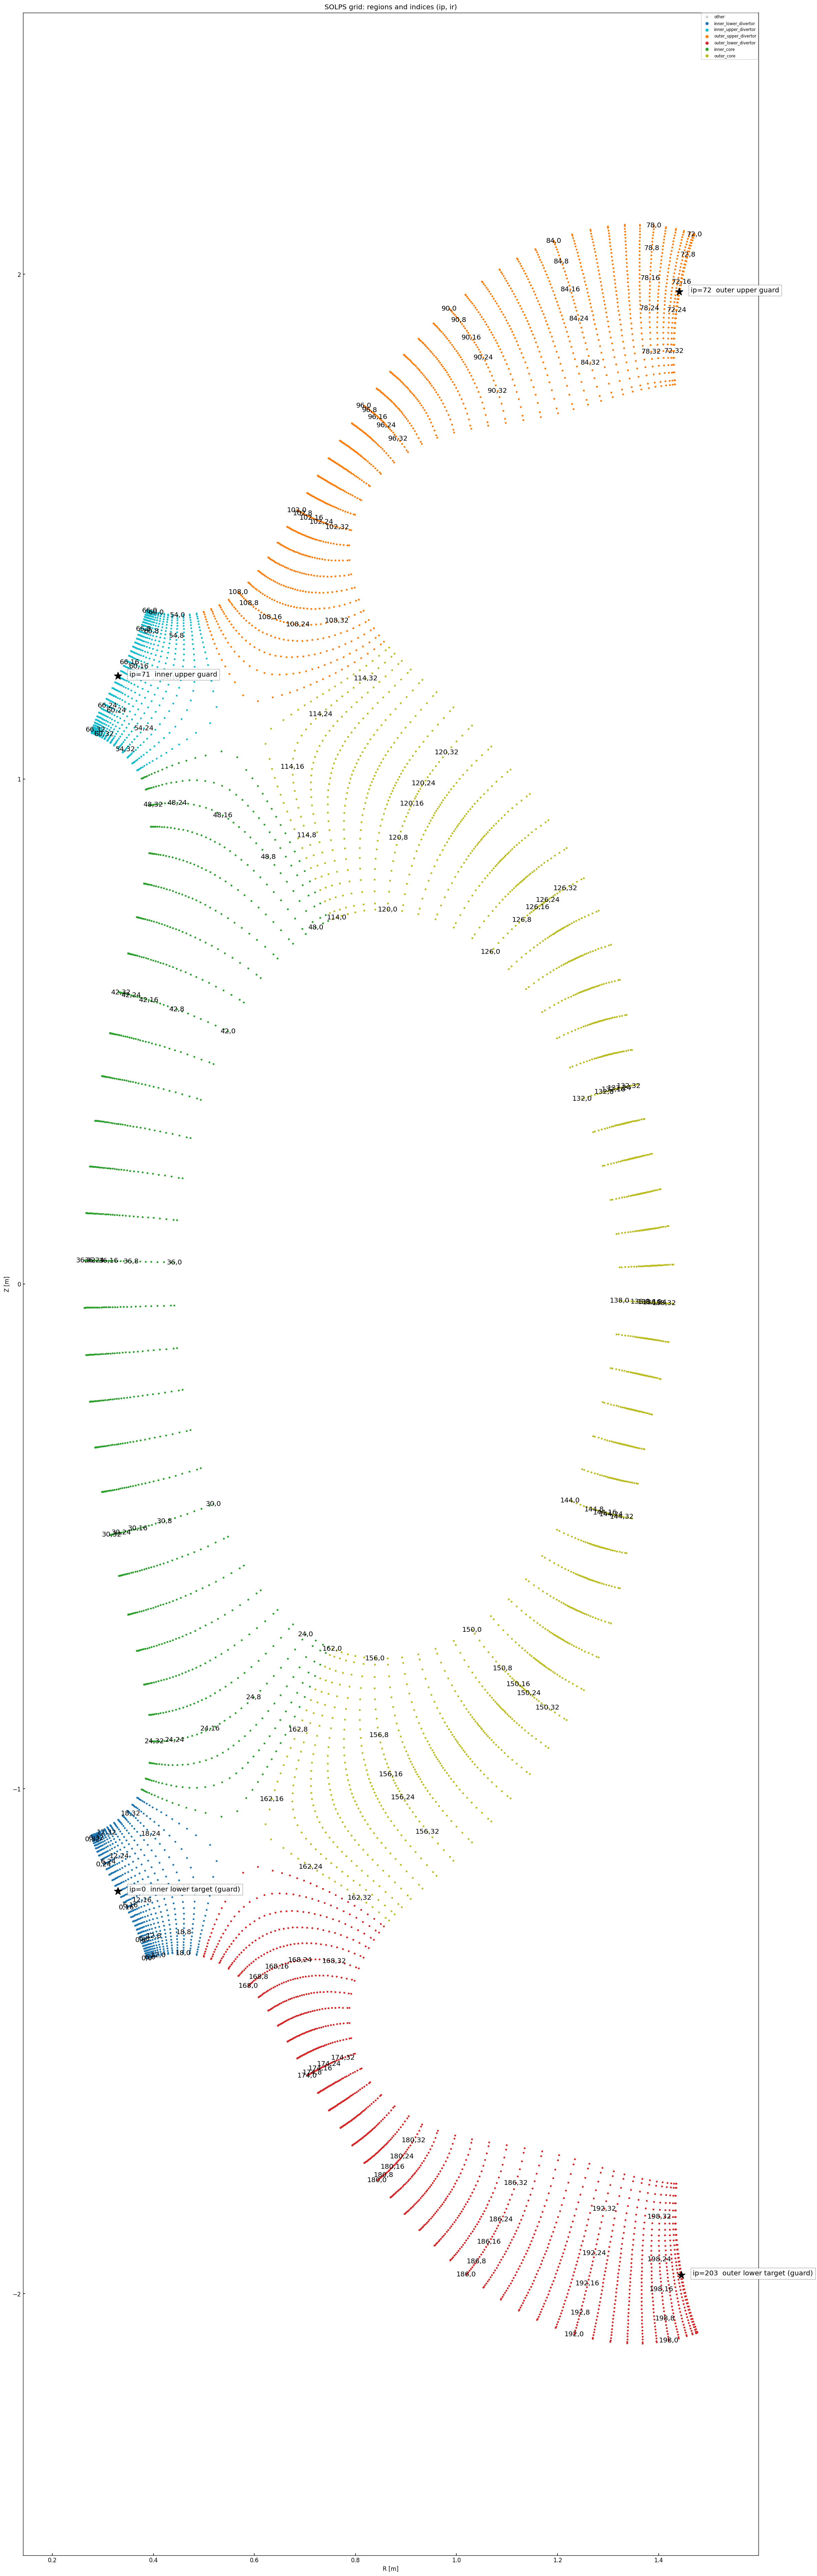

In [ ]:
sep = bal.g["sep"]

fig, ax = plt.subplots(figsize=(60, 80), dpi=120)

regions = {
    "inner_lower_divertor": "tab:blue",
    "inner_upper_divertor": "tab:cyan",
    "outer_upper_divertor": "tab:orange",
    "outer_lower_divertor": "tab:red",
    "inner_core":           "tab:green",
    "outer_core":           "tab:olive",
}

ax.scatter(Rs.ravel(), Zs.ravel(), c="lightgrey", s=4, label="other")
for name, col in regions.items():
    if name not in bal.psel:
        continue
    sl = bal.psel[name]
    ax.scatter(Rs[sl, :].ravel(), Zs[sl, :].ravel(), c=col, s=5, label=name)

# index labels, sparse so they stay readable
step_p, step_r = 6, 8
for ip in range(0, Rs.shape[0], step_p):
    for ir in range(0, Rs.shape[1], step_r):
        ax.text(Rs[ip, ir], Zs[ip, ir], f"{ip},{ir}",
                fontsize=12, ha="center", va="center", color="k")
upper_break = bal.g["upper_break"]
# key poloidal positions
key = [(0,                "ip=0  inner lower target (guard)"),
       (upper_break - 1,  f"ip={upper_break-1}  inner upper guard"),
       (upper_break,      f"ip={upper_break}  outer upper guard"),
       (Rs.shape[0] - 1,  f"ip={Rs.shape[0]-1}  outer lower target (guard)")]
print(f"Upper break = {upper_break}")
for ip, txt in key:
    ax.plot(Rs[ip, sep], Zs[ip, sep], "k*", ms=14)
    ax.annotate(txt, (Rs[ip, sep], Zs[ip, sep]), fontsize=12,
                xytext=(20, 0), textcoords="offset points",
                bbox=dict(fc="white", alpha=0.85, lw=0.3))

ax.set_aspect("equal")
ax.set_xlabel("R [m]")
ax.set_ylabel("Z [m]")
ax.set_title("SOLPS grid: regions and indices (ip, ir)")
ax.legend(fontsize=7, markerscale=2, loc="upper right")


## Guard cell

|                 | SOLPS                               | Hermes-3                               |
| --------------- | ----------------------------------- | -------------------------------------- |
| How many        | 1 radiak and poloidal on each side   | 2 radial (`MXG`), 2 poloidal (`MYG`)   |
| Always present? | Yes — baked into `balance.nc`       | Only if the case is loaded with guards |
| Physical size   | Very thin, near-zero volume         | Normal-sized, mirrored from the domain |
| Meaning         | Effectively the wall / target value | Boundary-condition storage             |


In [7]:
# Te_s = np.asarray(bal["Te"])

Ne_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
Te_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
Ti_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
Vi_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)

for ip in range(1, Rs.shape[0]): # loop poloidally
    for ir in range(1, Rs.shape[1]): # radially
        Ne_h[ir+2 ,ip+2] = bal.bal["Ne"][ip, ir]
        Te_h[ir+2 ,ip+2] = bal.bal["Te"][ip, ir]
        Ti_h[ir+2 ,ip+2] = bal.bal["Td+"][ip, ir]
        Vi_h[ir+2 ,ip+2] = bal.bal["Vd+"][ip, ir]
        if debug:
            
            print(f"ip = {ip}, ir = {ir}")
            # print(f"Ne in solps = {bal.bal["Ne"][ip, ir]}")
            



if debug:
    print(Ne_h.shape)
    ip, ir = 203, 37
    print(f"SOLPS Ne at {bal.bal["Ne"][ip, ir]}, Hermes-3 Ne at {Ne_h[ir+1, ip+1]}")
    for ip in range(1, mesh.Rxy.shape[0]): # loop poloidally
        for ir in range(1, mesh.Rxy.shape[1]): # radially
            print(Ne_h[ip,ir])

    has_zero = np.any(Ne_h == 0)  
    # print(has_zero)
    # print(idx)
    # for ip in range(1, Rh.shape[0]-1): # loop poloidally
        # for ir in range(1, Rh.shape[1]-1): # radially
            # print(Ne_h[ip,ir])      


ip = 1, ir = 1
ip = 1, ir = 2
ip = 1, ir = 3
ip = 1, ir = 4
ip = 1, ir = 5
ip = 1, ir = 6
ip = 1, ir = 7
ip = 1, ir = 8
ip = 1, ir = 9
ip = 1, ir = 10
ip = 1, ir = 11
ip = 1, ir = 12
ip = 1, ir = 13
ip = 1, ir = 14
ip = 1, ir = 15
ip = 1, ir = 16
ip = 1, ir = 17
ip = 1, ir = 18
ip = 1, ir = 19
ip = 1, ir = 20
ip = 1, ir = 21
ip = 1, ir = 22
ip = 1, ir = 23
ip = 1, ir = 24
ip = 1, ir = 25
ip = 1, ir = 26
ip = 1, ir = 27
ip = 1, ir = 28
ip = 1, ir = 29
ip = 1, ir = 30
ip = 1, ir = 31
ip = 1, ir = 32
ip = 1, ir = 33
ip = 1, ir = 34
ip = 1, ir = 35
ip = 1, ir = 36
ip = 1, ir = 37
ip = 2, ir = 1
ip = 2, ir = 2
ip = 2, ir = 3
ip = 2, ir = 4
ip = 2, ir = 5
ip = 2, ir = 6
ip = 2, ir = 7
ip = 2, ir = 8
ip = 2, ir = 9
ip = 2, ir = 10
ip = 2, ir = 11
ip = 2, ir = 12
ip = 2, ir = 13
ip = 2, ir = 14
ip = 2, ir = 15
ip = 2, ir = 16
ip = 2, ir = 17
ip = 2, ir = 18
ip = 2, ir = 19
ip = 2, ir = 20
ip = 2, ir = 21
ip = 2, ir = 22
ip = 2, ir = 23
ip = 2, ir = 24
ip = 2, ir = 25
ip = 2, ir = 26
ip = 2, ir

Try to redo it by myself

SOLPS guard cell: 0, 71, 72, 203 (domain start from 1 to 70, 73 to 202)

Hermes-3 will be 0,1; 72,73; 74,75; 206,207 (domain start from 2 to 71, 76 to 205)

Radially cell number 38 (0-37) (ny in solps) so loop from 1 to 36, hermes-3 loop from 2, 37

Guard cell filling: Hermes-3 should just take 

1 as solps 0, 

72 as solps 71, 

75 as solps 72,

206 as solps 203

In [ ]:
Ne_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
Te_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
Ti_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
Vi_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
print(f"Upper break = {bal.g["upper_break"]}")
print(f"Number of radial cell in solps = {bal.g["ny"]}")
print(f"Number of poloidal cell in solps = {bal.g["nx"]}")
fields_h = {"Ne": Ne_h, "Te": Te_h, "Ti": Ti_h, "Vi": Vi_h}
fields_s = {"Ne": bal.bal["Ne"],  "Te": bal.bal["Te"],
            "Ti": bal.bal["Td+"], "Vi": bal.bal["Vd+"]}

print("===============Inner part ====================")
# Inner part
for ip in range(1, bal.g["upper_break"]-1): # loop poloidally loop from 1 to 70
    for ir in range(1, Rs.shape[1]-1): # radially
        for k in fields_h:
            ip_h = ip+1
            ir_h = ir+1
            fields_h[k][ir_h, ip_h] = fields_s[k][ip, ir]
        # Ne_h[ir_h ,ip_h] = bal.bal["Ne"][ip, ir]
        # Te_h[ir_h ,ip_h] = bal.bal["Te"][ip, ir]
        # Ti_h[ir_h ,ip_h] = bal.bal["Td+"][ip, ir]
        # Vi_h[ir_h ,ip_h] = bal.bal["Vd+"][ip, ir]

        debug=False
        if debug:
            
            # print(f"ip = {ip}, ir = {ir}, and hermes-3 ip_h={ip_h}, ir_h={ir_h}")
            print(f"ip = {ip}, ir = {ir} Ne = {bal.bal["Ne"][ip, ir]:.3e}, and hermes-3 ip_h={ip_h}, ir_h={ir_h} Ne={Ne_h[ir_h ,ip_h]:.3e}")

            # print(f"Ne in solps = {bal.bal["Ne"][ip, ir]}")
print("===============Outer part ====================")
# Outer part
for ip in range(bal.g["upper_break"]+1, Rs.shape[0]-1): # loop poloidally loop from 73 to 202
    for ir in range(1, Rs.shape[1]-1): # radially
        for k in fields_h:
            ip_h = ip+3
            ir_h = ir+1
            fields_h[k][ir_h, ip_h] = fields_s[k][ip, ir] 

        debug = False
        if debug:
            
            print(f"ip = {ip}, ir = {ir} Ne = {bal.bal["Ne"][ip, ir]:.3e}, and hermes-3 ip_h={ip_h}, ir_h={ir_h} Ne={Ne_h[ir_h ,ip_h]:.3e}")
            # print(f"Ne in solps = {bal.bal["Ne"][ip, ir]}")
# Filling guard cell [radial, poloidal]
# for ir_h in range(0,2) or range(38, 40):
for ir_h in list(range(0, 2)) + list(range(38, 40)):
    for ir in range(0, Rs.shape[1]):

    
        # inner lower target two guard cell, same as SOLPS first guard cell 
        Ne_h[ir_h ,0]  =bal.bal["Ne"][0,  ir] 
        Ne_h[ir_h ,1]  =bal.bal["Ne"][0,  ir] 
        # inner upper target two guard cell, same as SOLPS first guard cell 
        Ne_h[ir_h ,72] =bal.bal["Ne"][71, ir] 
        Ne_h[ir_h ,73] =bal.bal["Ne"][71, ir] 
        # outer upper target two guard cell, same as SOLPS first guard cell 
        Ne_h[ir_h ,74] =bal.bal["Ne"][72, ir] 
        Ne_h[ir_h ,75] =bal.bal["Ne"][72, ir] 
        # outer lower target two guard cell, same as SOLPS first guard cell 
        Ne_h[ir_h ,206]=bal.bal["Ne"][203,ir] 
        Ne_h[ir_h ,207]=bal.bal["Ne"][203,ir] 

debug=True
if debug:
    for ip in range (0, Rs.shape[0]):
        for ir in range(0,Rs.shape[1]):
            print(f"SOLPS Ne = {bal.bal["Ne"][ip, ir]:.3e} at [{ip},{ir}], Hermes-3 Ne = {Ne_h[ir, ip]:.3e} at [{ip},{ir}]")
    for ip in range (0, Rs.shape[0]):
        for ir in range(0,Rs.shape[1]):
            print(f"SOLPS Ne = {bal.bal["Ne"][ip, ir]:.3e} at [{ip},{ir}], Hermes-3 Ne = {Ne_h[ir, ip]:.3e} at [{ip},{ir}]")
    print("blank poloidal columns:", np.where((Ne_h == 0).all(axis=0))[0])
    print("blank radial rows     :", np.where((Ne_h == 0).all(axis=1))[0])

Upper break = 72
Number of radial cell in solps = 38
Number of poloidal cell in solps = 204
===============Inner part ====================
===============Outer part ====================
SOLPS Ne = 1.156e+18 at [0,0], Hermes-3 Ne = 9.810e+17 at [0,0]
SOLPS Ne = 1.156e+18 at [0,1], Hermes-3 Ne = 9.810e+17 at [0,1]
SOLPS Ne = 1.161e+18 at [0,2], Hermes-3 Ne = 0.000e+00 at [0,2]
SOLPS Ne = 1.169e+18 at [0,3], Hermes-3 Ne = 0.000e+00 at [0,3]
SOLPS Ne = 1.182e+18 at [0,4], Hermes-3 Ne = 0.000e+00 at [0,4]
SOLPS Ne = 1.202e+18 at [0,5], Hermes-3 Ne = 0.000e+00 at [0,5]
SOLPS Ne = 1.230e+18 at [0,6], Hermes-3 Ne = 0.000e+00 at [0,6]
SOLPS Ne = 1.265e+18 at [0,7], Hermes-3 Ne = 0.000e+00 at [0,7]
SOLPS Ne = 1.308e+18 at [0,8], Hermes-3 Ne = 0.000e+00 at [0,8]
SOLPS Ne = 1.358e+18 at [0,9], Hermes-3 Ne = 0.000e+00 at [0,9]
SOLPS Ne = 1.417e+18 at [0,10], Hermes-3 Ne = 0.000e+00 at [0,10]
SOLPS Ne = 1.482e+18 at [0,11], Hermes-3 Ne = 0.000e+00 at [0,11]
SOLPS Ne = 1.552e+18 at [0,12], Hermes-3 N

Claude version

In [71]:
UPPER_BREAK = bal.g["upper_break"]      # 72
NPOL, NRAD = Rs.shape                   # 204, 38

print(f"Upper break = {UPPER_BREAK}")
print(f"SOLPS poloidal = {NPOL}, radial = {NRAD}")
print(f"Hermes shape   = {np.asarray(mesh.Rxy).shape}")

Ne_h = np.zeros_like(mesh.Rxy)
Te_h = np.zeros_like(mesh.Rxy)
Ti_h = np.zeros_like(mesh.Rxy)
Vi_h = np.zeros_like(mesh.Rxy)

fields_h = {"Ne": Ne_h, "Te": Te_h, "Ti": Ti_h, "Vi": Vi_h}
fields_s = {"Ne": bal.bal["Ne"],  "Te": bal.bal["Te"],
            "Ti": bal.bal["Td+"], "Vi": bal.bal["Vd+"]}

# --- copy every SOLPS cell, guards included ------------------------------
for ip in range(NPOL):
    ip_h = ip + 1 if ip < UPPER_BREAK else ip + 3
    for ir in range(NRAD):
        ir_h = ir + 1
        for k in fields_h:
            fields_h[k][ir_h, ip_h] = fields_s[k][ip, ir]

print("after copy:")
print("  blank poloidal columns:", np.where((Ne_h == 0).all(axis=0))[0])
print("  blank radial rows     :", np.where((Ne_h == 0).all(axis=1))[0])

# --- fill the Hermes cells that have no SOLPS partner --------------------
COL_SOURCE = {0: 1, 73: 72, 74: 75, 207: 206}

# [radial, poloidal cell]
for field in fields_h.values():
    for dst, src in COL_SOURCE.items():
        field[:, dst] = field[:, src]
    field[0,  :] = field[1,  :]
    field[-1, :] = field[-2, :]

print("after guard fill:")
for name, A in fields_h.items():
    print(f"  {name:3s} remaining zeros: {(A == 0).sum()}")
samples = [(0, 0), (1, 1), (35, 18), (70, 36), (71, 5),
           (72, 5), (73, 18), (150, 20), (203, 37)]

print(f"{'ip':>4} {'ir':>3} -> {'y_h':>4} {'x_h':>4}   {'SOLPS':>10} {'Hermes':>10}  ok")
for ip, ir in samples:
    ip_h = ip + 1 if ip < UPPER_BREAK else ip + 3
    ir_h = ir + 1
    a = bal.bal["Ne"][ip, ir]
    b = Ne_h[ir_h, ip_h]
    print(f"{ip:4d} {ir:3d} -> {ip_h:4d} {ir_h:4d}   {a:10.3e} {b:10.3e}  {a == b}")



Upper break = 72
SOLPS poloidal = 204, radial = 38
Hermes shape   = (40, 208)
after copy:
  blank poloidal columns: [  0  73  74 207]
  blank radial rows     : [ 0 39]
after guard fill:
  Ne  remaining zeros: 0
  Te  remaining zeros: 0
  Ti  remaining zeros: 0
  Vi  remaining zeros: 0
  ip  ir ->  y_h  x_h        SOLPS     Hermes  ok
   0   0 ->    1    1    1.156e+18  1.156e+18  True
   1   1 ->    2    2    1.158e+18  1.158e+18  True
  35  18 ->   36   19    2.894e+18  2.894e+18  True
  70  36 ->   71   37    9.813e+17  9.813e+17  True
  71   5 ->   72    6    1.207e+18  1.207e+18  True
  72   5 ->   75    6    1.099e+18  1.099e+18  True
  73  18 ->   76   19    7.244e+18  7.244e+18  True
 150  20 ->  153   21    2.894e+18  2.894e+18  True
 203  37 ->  206   38    6.881e+17  6.881e+17  True


#### Check whether the region are corresponded

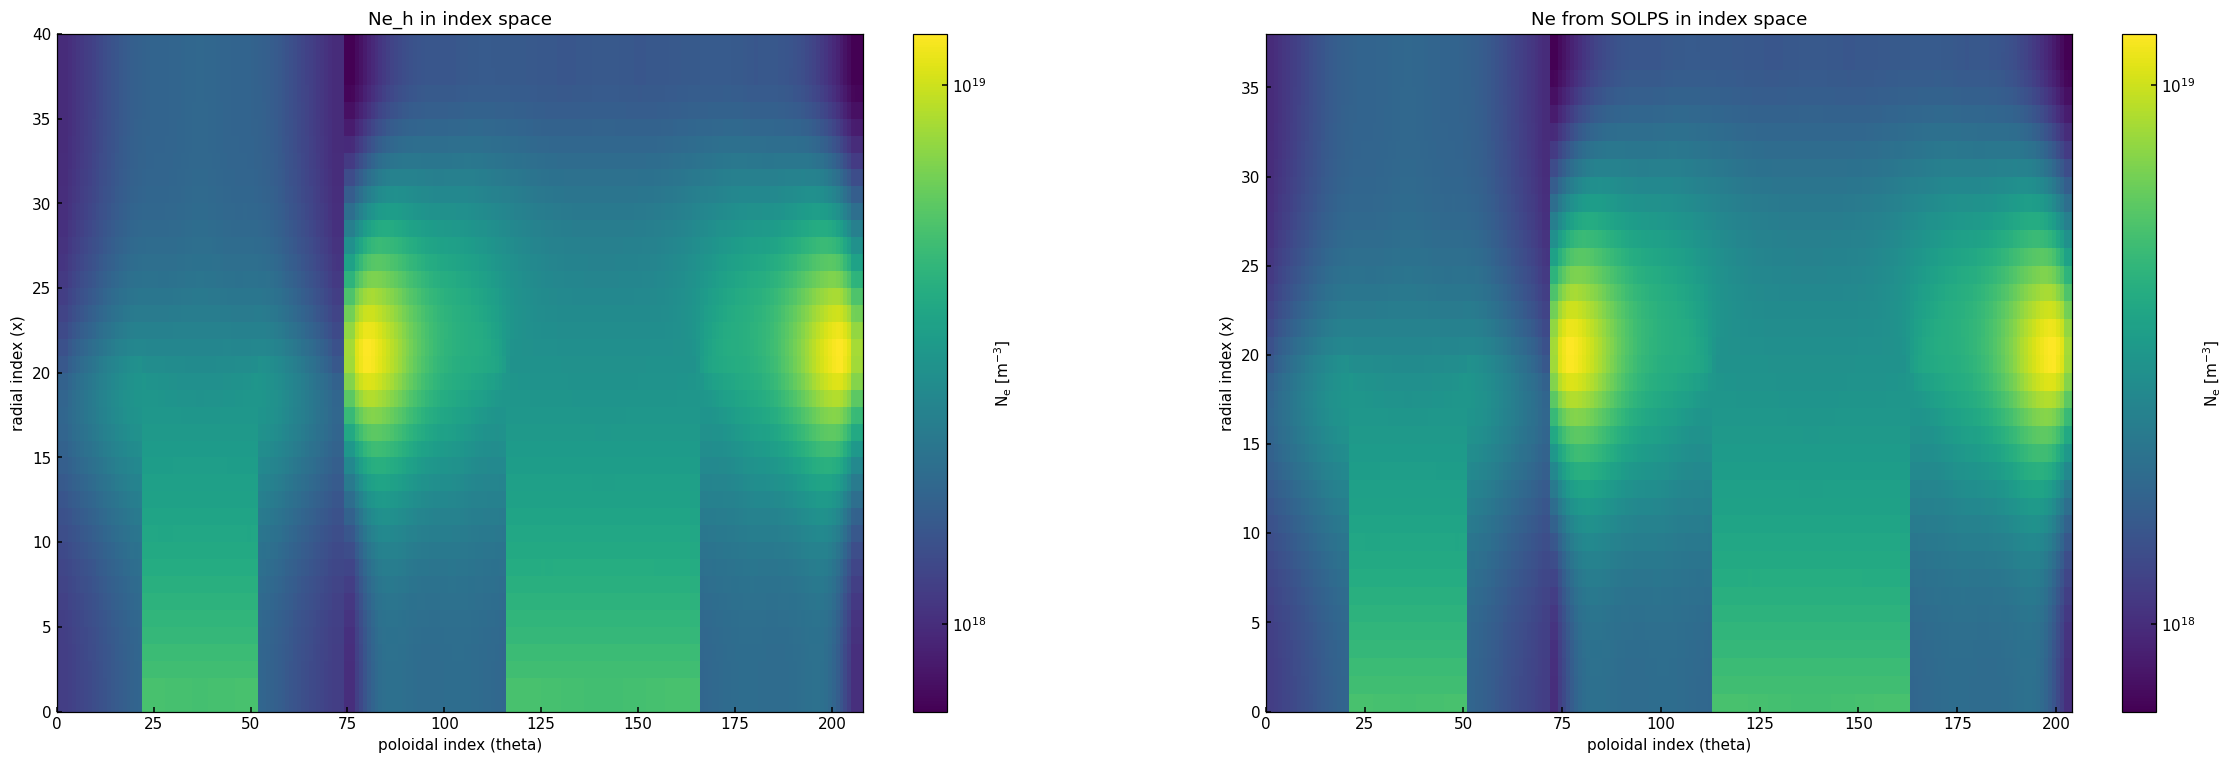

In [68]:
## Filling in guard cellimport matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# mask the unwritten cells so they show up blank
# A = Te_h
Ne_s = np.asarray(bal.bal["Ne"])
A = np.ma.masked_where(Ne_h <= 0, Ne_h)
B = np.ma.masked_where(Ne_s <= 0, Ne_s).T


fig, ax = plt.subplots(1,2, figsize=(26, 8), dpi=110)
im = ax[0].pcolormesh(A, norm=LogNorm(), cmap="viridis", shading="auto")
ax[0].set_xlabel("poloidal index (theta)")
ax[0].set_ylabel("radial index (x)")
ax[0].set_title("Ne_h in index space")
fig.colorbar(im, ax=ax[0], label=r"$N_e$ [m$^{-3}$]")

im = ax[1].pcolormesh(B, norm=LogNorm(), cmap="viridis", shading="auto")
ax[1].set_xlabel("poloidal index (theta)")
ax[1].set_ylabel("radial index (x)")
ax[1].set_title("Ne from SOLPS in index space")
fig.colorbar(im, ax=ax[1], label=r"$N_e$ [m$^{-3}$]")

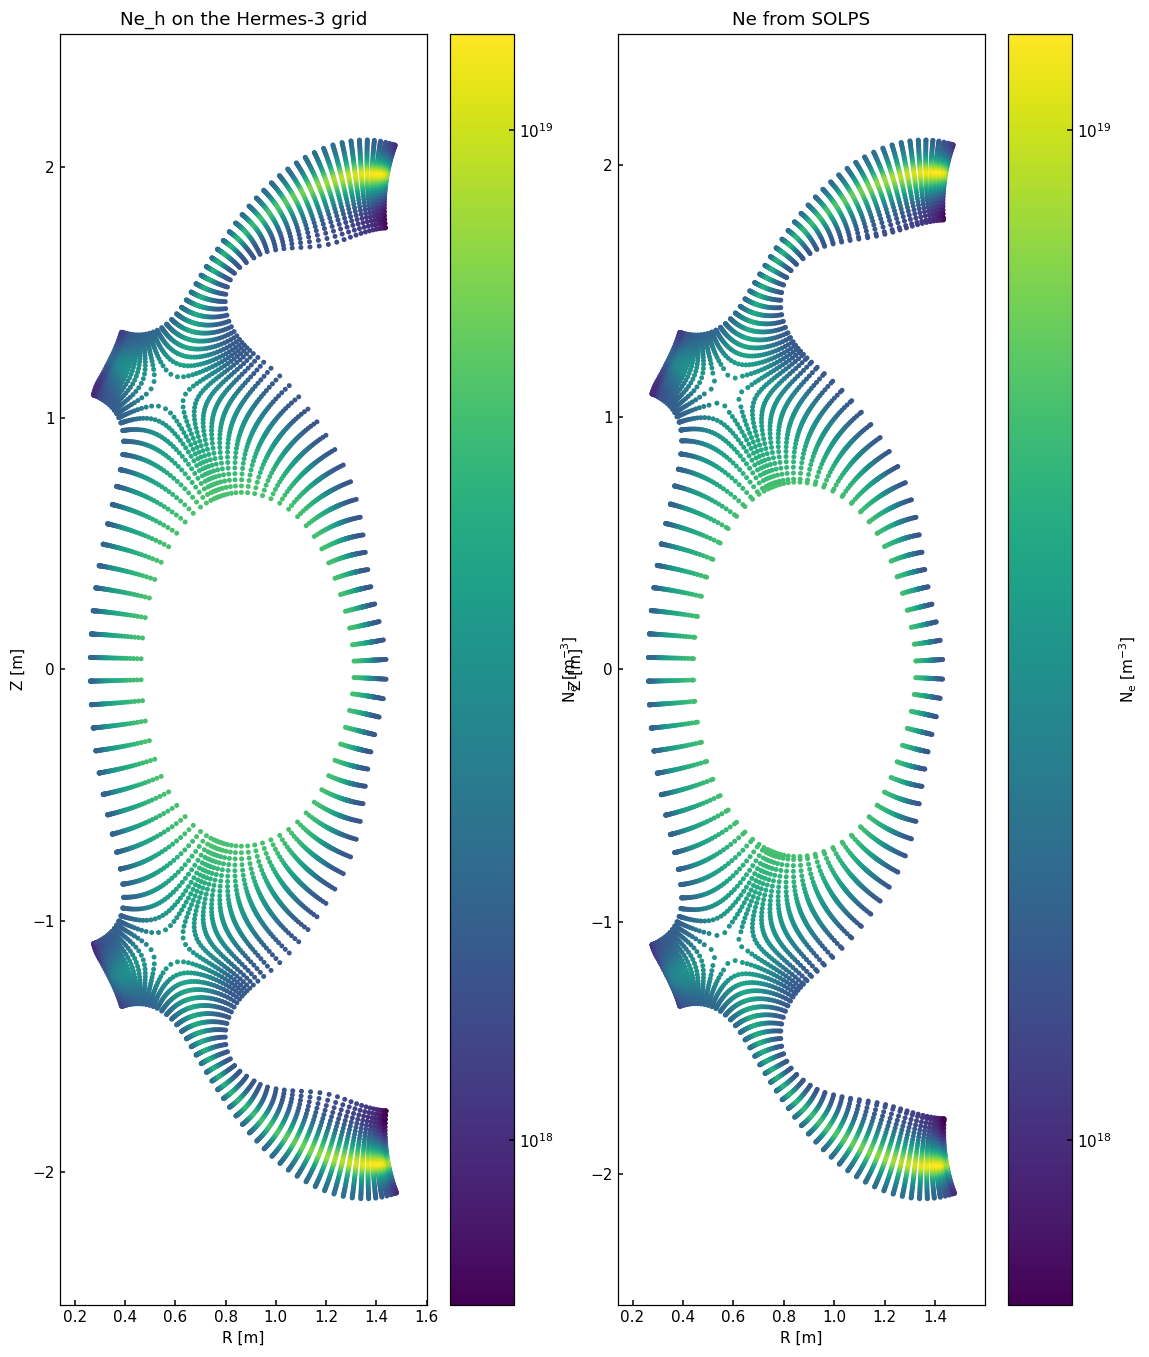

In [69]:
Rh = np.asarray(mesh.Rxy).ravel()
Zh = np.asarray(mesh.Zxy).ravel()

fig, ax = plt.subplots(1,2, figsize=(12,15), dpi=110)
sc = ax[0].scatter(Rh, Zh, c=A.ravel(), norm=LogNorm(), cmap="viridis", s=5)
ax[0].set_aspect("equal")
ax[0].set_xlabel("R [m]"); 
ax[0].set_ylabel("Z [m]")
ax[0].set_title("Ne_h on the Hermes-3 grid")
fig.colorbar(sc, ax=ax[0], label=r"$N_e$ [m$^{-3}$]")

sc = ax[1].scatter(Rs, Zs, c=bal.bal["Ne"].ravel(), norm=LogNorm(), cmap="viridis", s=5)
ax[1].set_aspect("equal")
ax[1].set_xlabel("R [m]"); 
ax[1].set_ylabel("Z [m]")
ax[1].set_title("Ne from SOLPS")
fig.colorbar(sc, ax=ax[1], label=r"$N_e$ [m$^{-3}$]")


In [ ]:
Ne_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
Te_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
Ti_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
Vi_h = np.zeros_like(mesh.Rxy) # (radial, poloidal)
print(f"Upper break = {bal.g["upper_break"]}")
print(f"Number of radial cell in solps = {bal.g["ny"]}")
print(f"Number of poloidal cell in solps = {bal.g["nx"]}")

# Inner part
for ip in range(1, bal.g["upper_break"]-1): # loop poloidally loop from 1 to 70
    for ir in range(1, Rs.shape[1]-1): # radially
        ip_h = ip+1
        ir_h = ir+1
        Ne_h[ir_h ,ip_h] = bal.bal["Ne"][ip, ir]
        Te_h[ir_h ,ip_h] = bal.bal["Te"][ip, ir]
        Ti_h[ir_h ,ip_h] = bal.bal["Td+"][ip, ir]
        Vi_h[ir_h ,ip_h] = bal.bal["Vd+"][ip, ir]
        if debug:
            
            print(f"ip = {ip}, ir = {ir}, and hermes-3 ip_h={ip_h}, ir_h={ir_h}")
            # print(f"Ne in solps = {bal.bal["Ne"][ip, ir]}")

# Outer part
for ip in range(bal.g["upper_break"]+1, Rs.shape[0]-1): # loop poloidally loop from 73 to 202
    for ir in range(1, Rs.shape[1]-1): # radially
        ip_h = ip+3
        ir_h = ir+1
        Ne_h[ir_h ,ip_h] = bal.bal["Ne"][ip, ir]
        Te_h[ir_h ,ip_h] = bal.bal["Te"][ip, ir]
        Ti_h[ir_h ,ip_h] = bal.bal["Td+"][ip, ir]
        Vi_h[ir_h ,ip_h] = bal.bal["Vd+"][ip, ir]
        if debug:
            
            print(f"ip = {ip}, ir = {ir}, and hermes-3 ip_h={ip_h}, ir_h={ir_h}")
            # print(f"Ne in solps = {bal.bal["Ne"][ip, ir]}")

            

Check the guard cell by leftix:  the x index of the cell physically to the left.

In [ ]:
leftix = np.asarray(bal.bal["leftix"]) + 1
iy = 1                                    # 任一徑向 ring
d = np.diff(leftix[:, iy])
cuts = np.where(d != 1)[0]

print("極向不連續點:", cuts)
print("xcut        :", bal.g["xcut"])
print("upper_break :", bal.g["upper_break"])
